# занятие 9



In [ ]:
import numpy as np
import sympy
import scipy.linalg
import numpy.linalg
from sympy import  Matrix, latex
import pandas as pd
import matplotlib.pyplot as plt
from skimage import io
from google.colab import files
from IPython.display import Latex

## Приближенное разложение меньшего ранга
$$
A_{n\times n} = A_{n\times r} \times  A_{r\times n},\quad
r - \mbox{ ранг матрицы А}.
$$
Пусть SVD-разложение матрицы $A = U\Sigma V^*$, где
$$
\Sigma =
\left(
\begin{matrix}
\sigma_1 & 0 & 0 & ... & 0\\
0 & \sigma_2 & 0 & ... & 0 \\
0 &0 & ...& ... & 0\\
0 & ... & ...& ... & 0 \\
0 &0 & ... & ... & \sigma_n
\end{matrix}
\right),
$$
тогда $A_r = U\Sigma_r V^*$, где
$$
\Sigma_r  =
\left(
\begin{matrix}
\sigma_1 & 0 & 0 & ... & ... & 0\\
0 & \sigma_2 & 0 & ... & ... &0 \\
0 &0 & ...& ... & ... & 0\\
0 & ... & ...& \sigma_r & ... & 0 \\
0 &0 & ... & ... &... & 0\\
 ...  & ...  & ... & ... &... &  ... \\
0 &0 & ... & ... &... & 0\\
\end{matrix}
\right),
$$
## Задание 1
Считать из файла 'sem_9_task_01.xlsx' матрицу $A_1$.
Построить приближение ранга, равного 25\% размерности матрицы $A_1$ (в спектральной норме), найти норму разности матриц $A_1$ и ее приближения меньшего ранга.

In [ ]:
uploaded = files.upload()
for file_name in uploaded.keys():
    print(f'Загружен файл {file_name}')
df = pd.read_excel(file_name, header=None)
A1 = df.to_numpy()
u1, sigma1, vh1 = scipy.linalg.svd(A1)
k = (min(A1.shape)//4)
A1r = u1[:, :k] @ np.diag(sigma1[:k]) @ vh1[:k, :]
print(f'scipy.linalg.norm(A1 - A1r) = {round(scipy.linalg.norm(A1 - A1r, 2), 1)}, \
ранг A1r = {np.linalg.matrix_rank(A1r)}')

Saving sem_9_task_01.xlsx to sem_9_task_01 (4).xlsx
Загружен файл sem_9_task_01 (4).xlsx
scipy.linalg.norm(A1 - A1r) = 777.7, ранг A1r = 38


# Задание 2.
Представить изображение в оттенках серого в виде матрицы, построить приближения меньшего ранга (10, 15, 25% от $k$ - минимального из чисел $m$ и $n$), вывести их изображения на экран.

Saving ель.jpg to ель.jpg
User uploaded file "ель.jpg" with length 87496 bytes
50%


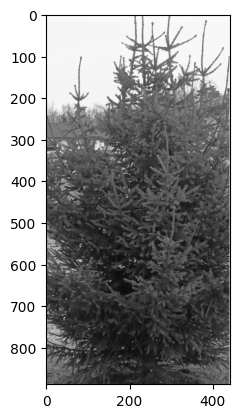

25%


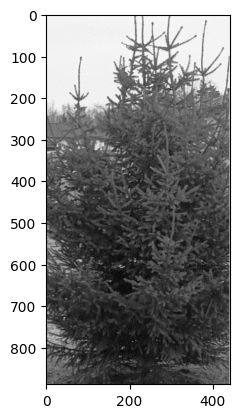

10%


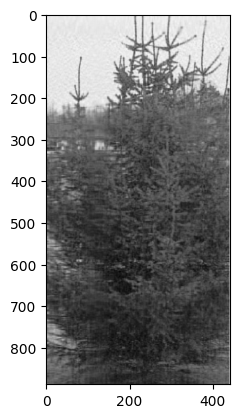

In [ ]:
uploaded = files.upload()
for fn in uploaded.keys():
  print('User uploaded file "{name}" with length {length} bytes'.format(name=fn, length=len(uploaded[fn])))

img = io.imread(fn, as_gray=True)
u, s, vh = np.linalg.svd(img, full_matrices=True)
k = min(img.shape)
for i in (50, 25, 10):
    t = k * i // 100
    imgplot = plt.imshow(u[:, :t] @ np.diag(s[:t]) @ vh[:t, :], cmap='Greys_r')
    print(f'{i}%')
    plt.show()

## Задание 3
Считать из файла 'sem_9_task_3.xlsx' матрицу $A_3$.
Построить матрицу $Ar_3$ - приближение меньшего ранга матрицы $A_3$ (в спектральной норме), такое что норма разности матриц $A_3$ и ее приближения меньшего ранга не превосходит 10\% от нормы матрицы $A_3$.

Записать на отдельные листы файла 'sem_9_task_3_ans.xlsx' компоненты svd разложения матрицы $A_3$  и матрицу $Ar_3$, являющуюся ее приближением меньшего ранга. Вывести на экран первые 10 наибольших сингулярных чисел матрицы $A_3$ и ранг $Ar_3$.

In [ ]:
uploaded = files.upload()
for file_name in uploaded.keys():
    print(f'Загружен файл {file_name}')
A3 = pd.read_excel("sem_9_task_3.xlsx", header=None)
A3 = A3.to_numpy()
u3, sigma3, vh3 = np.linalg.svd(A3)
norm_A3 = sigma3[0]
priblij = 0.1*norm_A3
r_min = 0
for r in range(1, len(sigma3) + 1):
    Ar3 = u3[:, :r] @ np.diag(sigma3[:r]) @ vh3[:r, :]
    norm_diff = scipy.linalg.norm(A3 - Ar3, 2)
    if norm_diff <= priblij:
        print(f'норма разности: {norm_diff}')
        r_min = r
        print(f'ранг {r_min}')
        break
file_name_res = 'sem_9_task_3_ans.xlsx'
U3 = pd.DataFrame(np.array(u3))
Sigma = pd.DataFrame(np.array(sigma3))
VH3 = pd.DataFrame(np.array(vh3))
AR3 = pd.DataFrame(np.array(Ar3))
with pd.ExcelWriter(file_name_res) as writer:
    VH3.to_excel(writer, sheet_name='VH3', header=False, index=False)
    Sigma.to_excel(writer, sheet_name='Sigma', header=False, index=False)
    U3.to_excel(writer, sheet_name='U', header=False, index=False)
    AR3.to_excel(writer, sheet_name='AR3', header=False, index=False)
files.download(file_name_res)
print(sigma3[:10], sep = ', ')

Saving sem_9_task_3.xlsx to sem_9_task_3 (5).xlsx
Загружен файл sem_9_task_3 (5).xlsx
норма разности: 286.5723411588218
ранг 12


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

[2913.30345083  410.52650691  394.37649852  389.24488258  379.1995514
  374.00943173  356.96166284  336.06320887  329.30420785  320.82669535]


## Задание 4
Построить матрицу $Ar_4$ - приближение меньшего ранга матрицы $A_3$ (в спектральной норме), ранг $Ar_4$ равен количеству сингулярных чисел матрицы $A_3$ (из разложения Задания 3), которые не меньше, чем 10\% максимального сингулярного числа.

В компонентах разложения матрицы $A_3$ округлить все числа до десятых, вычислить $Ar_{4rounded}$.

Вывести на экран спектральную норму разности $A_3$ и $Ar_4$, $A_3$ и $Ar_{4rounded}$, $Ar_4$ и $Ar_{4rounded}$.

In [ ]:
rank_ar4 = 0
mx = max(sigma3)*0.1
print(mx)
for item in sigma3:
    if item>=mx:
        rank_ar4 += 1
print(f' ранг: {rank_ar4}')
Ar4 = u3[:, :rank_ar4] @ np.diag(sigma3[:rank_ar4]) @ vh3[:rank_ar4, :]
u4 = np.round(u3, 1)
sigma4 = np.round(sigma3, 1)
vh4 = np.round(vh3, 1)
Ar4_round = u4[:, :rank_ar4] @ np.diag(sigma4[:rank_ar4]) @ vh4[:rank_ar4, :]
norm_diff1 = scipy.linalg.norm(A3 - Ar4, 2)
norm_diff2 = scipy.linalg.norm(A3 - Ar4_round, 2)
norm_diff3 = scipy.linalg.norm(Ar4 - Ar4_round, 2)
print(norm_diff1)
print(norm_diff2)
print(norm_diff3)
diff_u = np.linalg.norm(u3 - u4, 2)
diff_sigma = np.linalg.norm(sigma3 - sigma4, 2)
diff_vh = np.linalg.norm(vh3 - vh4, 2)

print(f"Изменение U после округления: {diff_u:.4f}")
print(f"Изменение Sigma после округления: {diff_sigma:.4f}")
print(f"Изменение Vh после округления: {diff_vh:.4f}")

291.3303450830126
 ранг: 12
286.5723411588218
1148.0377903715992
1145.9577534895575
Изменение U после округления: 0.4005
Изменение Sigma после округления: 0.1922
Изменение Vh после округления: 0.4417


## Задание 5
Найти собственные и сингулярные числа наибольшей подматрицы матрицы $Ar_4$ (приближение меньшего ранга матрицы $A_3$), находящейся в левом верхнем углу матрицы $Ar_4$.

Изобразить на графике точками собственные и сингулярные числа, а также окружности радиуса, равного спектральному радиусу и сингулярному радиусу.

## Задание 6
Считать матрицу $A6$ из файла 'sem_9_task_6.xlsx'.
Используя разложение SVD матрицы $A_6$ показать, что столбцы матрицы $U$ ортогональны, т.е. их скалярное произведение 0. (Подсказка - перемножить транспонированный столбец на другой столбец).

Проверить, что квадраты диагональных элементов матрицы $\Sigma$ являются собственными числами матрицы $A^TA$, соответствующим собственным векторам, записанным в строках матрицы $Vh$ разложения  SVD, т.е. что $A^TAx - \lambda x$ вектор из машинных нулей, где $x$ строка матрицы $Vh$, записанная в столбец (чтобы можно было перемножить $A^TAx$).

Показать, что если $x$ собственный вектор, $\sigma$ - ненулевое собственное число матрицы $A^TA$, то $\frac{1}{\sigma}A x$ с точностью до машинного нуля совпадает со столбцом матрицы $U$, соответствующим $\sigma$.

## Задание 7

Разведчик решил передать изображение в виде файла xlsx с svd разложением картинки. Чтобы в случае перехвата сложнее было восстановить картинку, он транспонировал одну из матриц, а сингулярные числа сделал надписями строк или столбцов одной из матриц.

Считать из файла "sem_9_task_7.xlsx" матрицы svd разложения, восстановить и вывести на экран изображение, которое хотел передать разведчик.

## Задание 4
Для матрицы $B$ из файла `data_var2.xlsx` (лист `SVD_Matrix`) выполнить SVD-разложение. На основе полученных матриц $U$, $\Sigma$, $V^T$ составить псевдообратную матрицу $B^+$.

Записать в новый файл `svd_result.xlsx` на листы 'U', 'Sigma', 'VT', 'B_pinv' компоненты разложения и псевдообратную матрицу (без подписей строк и столбцов).

Вывести на экран первые 3 строки и 4 столбца каждой из матриц $U$, $V^T$, $B^+$, а также первые 3 сингулярных числа.

In [ ]:
uploaded = files.upload()
for file_name in uploaded.keys():
    print(f'Загружен файл {file_name}')
B = pd.read_excel("data_var2.xlsx", sheet_name="SVD_Matrix", header=None)
B = B.to_numpy()
B_star_B = B.T @ B
display(Latex(f'B^*B = {latex(B_star_B)}'),
        B_star_B)

Saving data_var2.xlsx to data_var2.xlsx
Загружен файл data_var2.xlsx


<IPython.core.display.Latex object>

array([[ 2151,   616, -1619,   558,   773,  -417, -1499,  -360],
       [  616,  3273, -2104,  1860,  2847, -3473, -1481, -1014],
       [-1619, -2104,  4508,  -561, -1403,  2368,  2541,  -750],
       [  558,  1860,  -561,  1684,  1800, -2001,  -664,  -875],
       [  773,  2847, -1403,  1800,  2672, -2916, -1224, -1278],
       [ -417, -3473,  2368, -2001, -2916,  3805,  1512,   802],
       [-1499, -1481,  2541,  -664, -1224,  1512,  1712,    46],
       [ -360, -1014,  -750,  -875, -1278,   802,    46,  1379]])

In [ ]:
B_star_B_eigen_vals, B_star_B_eigen_vects = np.linalg.eig(B_star_B)
print(r"""Собственные числа
{},
собственные векторы
{}""".format(B_star_B_eigen_vals.round(2), B_star_B_eigen_vects.round(2)))

Собственные числа
[1.372521e+04 4.795460e+03 2.161780e+03 4.674600e+02 2.212000e+01
 9.320000e+00 1.000000e-02 2.640000e+00],
собственные векторы
[[ 0.18  0.31  0.75  0.14 -0.07  0.47 -0.19 -0.16]
 [ 0.47 -0.2  -0.14 -0.2  -0.34 -0.02 -0.72  0.21]
 [-0.41 -0.65  0.24  0.09 -0.22  0.33  0.06  0.42]
 [ 0.27 -0.27  0.15  0.8   0.05 -0.43 -0.02 -0.05]
 [ 0.41 -0.27  0.12 -0.21  0.78  0.13  0.08  0.26]
 [-0.5   0.2   0.33 -0.11  0.29 -0.49 -0.46  0.26]
 [-0.29 -0.32 -0.19  0.09  0.3   0.24 -0.43 -0.66]
 [-0.11  0.38 -0.42  0.48  0.19  0.41 -0.21  0.42]]


In [ ]:
B_star_B_eigen_vals.sort()
B_star_B_eigen_vals_reversed = np.flip(B_star_B_eigen_vals)
display(B_star_B_eigen_vals.round(2), B_star_B_eigen_vals_reversed.round(2))

array([9.80082077e-03, 2.63830123e+00, 9.32457788e+00, 2.21227648e+01,
       4.67458143e+02, 2.16178203e+03, 4.79545630e+03, 1.37252081e+04])

array([1.37252081e+04, 4.79545630e+03, 2.16178203e+03, 4.67458143e+02,
       2.21227648e+01, 9.32457788e+00, 2.63830123e+00, 9.80082077e-03])

In [ ]:
sigmas = [round(np.sqrt(item), 1) for item in B_star_B_eigen_vals_reversed if item > 0]
sigmas

[np.float64(117.2),
 np.float64(69.2),
 np.float64(46.5),
 np.float64(21.6),
 np.float64(4.7),
 np.float64(3.1),
 np.float64(1.6),
 np.float64(0.1)]

In [ ]:
Sigma = np.hstack((np.diag(sigmas), np.zeros((8, 1))))
Sigma

array([[1.172e+02, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00],
       [0.000e+00, 6.920e+01, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00],
       [0.000e+00, 0.000e+00, 4.650e+01, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00],
       [0.000e+00, 0.000e+00, 0.000e+00, 2.160e+01, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00],
       [0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 4.700e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00],
       [0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 3.100e+00,
        0.000e+00, 0.000e+00, 0.000e+00],
       [0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        1.600e+00, 0.000e+00, 0.000e+00],
       [0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 1.000e-01, 0.000e+00]])

In [ ]:
e8, e7, e6, e5, e4, e3, e2, e1 = [item.reshape((8, 1)) for item in  B_star_B_eigen_vects.T]
B_star_B_eigen_vects_new = [e8, e7, e6, e5, e4, e3, e2, e1]
print(*[item.round(2).T for item in B_star_B_eigen_vects], sep='\n')
np.round(B_star_B_eigen_vects, 3)

[ 0.18  0.31  0.75  0.14 -0.07  0.47 -0.19 -0.16]
[ 0.47 -0.2  -0.14 -0.2  -0.34 -0.02 -0.72  0.21]
[-0.41 -0.65  0.24  0.09 -0.22  0.33  0.06  0.42]
[ 0.27 -0.27  0.15  0.8   0.05 -0.43 -0.02 -0.05]
[ 0.41 -0.27  0.12 -0.21  0.78  0.13  0.08  0.26]
[-0.5   0.2   0.33 -0.11  0.29 -0.49 -0.46  0.26]
[-0.29 -0.32 -0.19  0.09  0.3   0.24 -0.43 -0.66]
[-0.11  0.38 -0.42  0.48  0.19  0.41 -0.21  0.42]


array([[ 0.181,  0.314,  0.75 ,  0.142, -0.067,  0.468, -0.19 , -0.164],
       [ 0.468, -0.204, -0.142, -0.196, -0.339, -0.025, -0.721,  0.212],
       [-0.414, -0.651,  0.235,  0.091, -0.224,  0.332,  0.062,  0.421],
       [ 0.267, -0.271,  0.154,  0.801,  0.048, -0.43 , -0.02 , -0.048],
       [ 0.405, -0.273,  0.117, -0.208,  0.784,  0.133,  0.076,  0.257],
       [-0.496,  0.196,  0.328, -0.106,  0.289, -0.487, -0.456,  0.259],
       [-0.287, -0.322, -0.189,  0.086,  0.303,  0.244, -0.427, -0.661],
       [-0.113,  0.383, -0.425,  0.479,  0.194,  0.414, -0.209,  0.422]])

In [ ]:
n, m = B_star_B_eigen_vects.shape
e8, e7, e6, e5, e4, e3, e2, e1 = [B_star_B_eigen_vects[:, k].reshape((8, 1)) for k in range(m)]
print(e8, e7, e6, e5, e4, e3, e2, e1, sep='\n')

[[ 0.18128296]
 [ 0.46828385]
 [-0.41399495]
 [ 0.26702354]
 [ 0.40501135]
 [-0.49612874]
 [-0.28681789]
 [-0.11274267]]
[[ 0.31354729]
 [-0.20372395]
 [-0.6505424 ]
 [-0.27099983]
 [-0.2727407 ]
 [ 0.19584055]
 [-0.3223004 ]
 [ 0.38330115]]
[[ 0.75028202]
 [-0.14191   ]
 [ 0.23528552]
 [ 0.15413206]
 [ 0.11704662]
 [ 0.3284189 ]
 [-0.18946707]
 [-0.42469496]]
[[ 0.14154932]
 [-0.19602966]
 [ 0.09098333]
 [ 0.80117495]
 [-0.2084436 ]
 [-0.10643228]
 [ 0.08550775]
 [ 0.47884106]]
[[-0.06658032]
 [-0.33927282]
 [-0.22360902]
 [ 0.04834801]
 [ 0.78430744]
 [ 0.2890867 ]
 [ 0.30297948]
 [ 0.19395011]]
[[ 0.46760441]
 [-0.02453999]
 [ 0.33231992]
 [-0.42965416]
 [ 0.1332957 ]
 [-0.48712012]
 [ 0.24404678]
 [ 0.4136328 ]]
[[-0.18977513]
 [-0.72100424]
 [ 0.06186663]
 [-0.02031027]
 [ 0.07569196]
 [-0.45640511]
 [-0.42676525]
 [-0.20912872]]
[[-0.16359657]
 [ 0.21233308]
 [ 0.42130811]
 [-0.04761094]
 [ 0.25650438]
 [ 0.25913933]
 [-0.66118426]
 [ 0.42222173]]


In [ ]:
e8, e7, e6, e5, e4, e3, e2, e1 = [item / np.linalg.norm(item) for item in B_star_B_eigen_vects_new]
P = np.hstack((e8, e7, e6, e5, e4, e3, e2, e1))
display(Latex(f'P = {latex(Matrix(P.round(2)))}'))

<IPython.core.display.Latex object>

In [ ]:
f1, f2, f3, f4, f5, f6, f7, f8 = [B @ ei / sigmas[i] for i, ei in enumerate((e8, e7, e6, e5, e4, e3, e2, e1))]
Q = np.hstack((f1, f2, f3, f4, f5, f6, f7, f8))
Sig = np.hstack((np.diag(sigmas)))
display(*[item.evalf(5) for item in map(Matrix, (Q, Sig, P, Q @ Sig @ P.T))])
Sig = np.hstack((np.diag(sigma), np.zeros((8, 1)))
files.download(file_name_res)

SyntaxError: incomplete input (4199919232.py, line 5)

In [ ]:
Q, sigma, P = scipy.linalg.svd(B)
Sigma_plus = np.vstack((np.diag([1 / item for item in sigma])))
B_pinv_my = P @ Sigma_plus @ Q
print('V**T')
print(Q)
print('Sigma')
print(Sigma_plus)
print('U')
print(P)
print('B+')
print(B_pinv_my)
file_name_res = 'svd_result.xlsx'
QQ = pd.DataFrame(np.array(Q.T))
SSigma = pd.DataFrame(np.array(Sigma_plus))
PP = pd.DataFrame(np.array(P))
BB_pinv_my = pd.DataFrame(np.array(B_pinv_my))
with pd.ExcelWriter(file_name_res) as writer:
    QQ.to_excel(writer, sheet_name='VT', header=False, index=False)
    SSigma.to_excel(writer, sheet_name='Sigma', header=False, index=False)
    PP.to_excel(writer, sheet_name='U', header=False, index=False)
    BB_pinv_my.to_excel(writer, sheet_name='B+', header=False, index=False)
files.download(file_name_res)
print(f'первые три сигмы: {sigma[:3]}')
print(f'первые три строки и 4 столбца для U: {P[:3, :4]}')
print(f'первые три строки и 4 столбца для VT: {Q[:3, :4]}')
print(f'первые три строки и 4 столбца для B+: {B_pinv_my[:3, :4]}')


V**T
[[-0.18128296  0.31354729 -0.75028202 -0.14154932  0.06658032  0.46760441
  -0.16359657  0.18977513]
 [-0.46828385 -0.20372395  0.14191     0.19602966  0.33927282 -0.02453999
   0.21233308  0.72100424]
 [ 0.41399495 -0.6505424  -0.23528552 -0.09098333  0.22360902  0.33231992
   0.42130811 -0.06186663]
 [-0.26702354 -0.27099983 -0.15413206 -0.80117495 -0.04834801 -0.42965416
  -0.04761094  0.02031027]
 [-0.40501135 -0.2727407  -0.11704662  0.2084436  -0.78430744  0.1332957
   0.25650438 -0.07569196]
 [ 0.49612874  0.19584055 -0.3284189   0.10643228 -0.2890867  -0.48712012
   0.25913933  0.45640511]
 [ 0.28681789 -0.3223004   0.18946707 -0.08550775 -0.30297948  0.24404678
  -0.66118426  0.42676525]
 [ 0.11274267  0.38330115  0.42469496 -0.47884106 -0.19395011  0.4136328
   0.42222173  0.20912872]]
Sigma
[[8.53572729e-03 0.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 1.44405931e-02 0.00000000e+00 0.00000000

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

первые три сигмы: [117.1546332   69.24923323  46.49496778]
первые три строки и 4 столбца для U: [[-0.18128296 -0.46828385  0.41399495 -0.26702354]
 [ 0.31354729 -0.20372395 -0.6505424  -0.27099983]
 [-0.75028202  0.14191    -0.23528552 -0.15413206]]
первые три строки и 4 столбца для VT: [[-0.18128296  0.31354729 -0.75028202 -0.14154932]
 [-0.46828385 -0.20372395  0.14191     0.19602966]
 [ 0.41399495 -0.6505424  -0.23528552 -0.09098333]]
первые три строки и 4 столбца для B+: [[ 0.30495436  0.43335188  0.47383927 -0.55309379]
 [ 0.43335188  1.59031733  1.59524639 -1.8318942 ]
 [ 0.47383927  1.59524639  1.88961385 -2.07330227]]
